# CE4 Case Study: Tyre Age, Fuel Load and Lap Time at the 2026 Japanese Grand Prix

**Course:** Regression Techniques and Time Series Analysis (Continuous Evaluation 4)
**Data:** OpenF1 API (openf1.org), Mercedes race laps, Suzuka, 29 March 2026

## Problem and research questions
Over a race, a Formula 1 car gets **lighter** (fuel burns off, which makes laps faster) while its tyres **wear** (which makes laps slower). Which effect wins at Suzuka, and does the pace differ by tyre compound and driver?

1. **RQ1 (regression):** How do lap number, tyre compound and driver explain Mercedes lap times?
2. **RQ2 (inference):** Are these effects statistically significant, and how large are they (confidence intervals)?
3. **RQ3 (diagnostics):** Do the OLS assumptions hold, especially independence of consecutive laps?
4. **RQ4 (time series):** Within one clean stint, do lap times show autocorrelation that an AR, MA or ARMA model can capture?

## Hypotheses (tested at the 5% level)
- For each coefficient: H0: beta = 0 against H1: beta != 0.
- Overall model: H0: all slope coefficients = 0 (F-test).
- Time series: H0: residuals are white noise (Ljung-Box).

## Notebook map
1. Setup  2. Data collection  3. Data preparation  4. Exploratory analysis  5. Multicollinearity  6. Regression models and inference  7. Model diagnostics  8. Time series (AR, MA, ARMA)  9. Forecast comparison

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import time

In [3]:
os.makedirs('cache', exist_ok=True)

## 2. Data collection (OpenF1 API)
The data was collected through an open source called openf1 and we have retrieved 2026 Suzuka Grand Prix values to perform the case study.

In [4]:
import requests

BASE = "https://api.openf1.org/v1"

def get(endpoint, **params):
    r = requests.get(f"{BASE}/{endpoint}", params=params, timeout=30)
    r.raise_for_status()
    return pd.DataFrame(r.json())

sessions = get("sessions", year=2026, country_name="Japan", session_name="Race")
sessions

,session_key,session_type,session_name,date_start,date_end,meeting_key,circuit_key,circuit_short_name,country_key,country_code,country_name,location,gmt_offset,year,is_cancelled
0,11253,Race,Race,2026-03-29T05:00:00+00:00,2026-03-29T07:00:00+00:00,1281,46,Suzuka,4,JPN,Japan,Suzuka,09:00:00,2026,False


**Result:** one session found, `session_key = 11253`, the Race at Suzuka on 29 March 2026.

finding the two Mercedes drivers in that session.

In [ ]:
sk = sessions.loc[0, "session_key"]   

drivers = get("drivers", session_key=sk)
merc_drivers = drivers[drivers["team_name"] == "Mercedes"]
merc_drivers[["driver_number", "name_acronym", "team_name"]]

,driver_number,name_acronym,team_name
6,12,ANT,Mercedes
18,63,RUS,Mercedes


**Result:** Mercedes ran Antonelli (#12, ANT) and Russell (#63, RUS).

Downloaded three tables for both drivers: **laps** (one row per driver per lap), **stints** (which tyre was fitted from which lap to which lap) and **weather** (about one reading per minute). `time.sleep(1)` keeps us under OpenF1's rate limit.

In [6]:
laps_list, stints_list = [], []
for num in merc_drivers["driver_number"]:
    laps_list.append(get("laps", session_key=sk, driver_number=num))
    time.sleep(1)
    stints_list.append(get("stints", session_key=sk, driver_number=num))
    time.sleep(1)

laps = pd.concat(laps_list, ignore_index=True)
stints = pd.concat(stints_list, ignore_index=True)
weather = get("weather", session_key=sk)

print(laps.shape, stints.shape, weather.shape)
laps.head()

(106, 16) (4, 8) (156, 10)


,meeting_key,session_key,driver_number,lap_number,date_start,duration_sector_1,duration_sector_2,duration_sector_3,i1_speed,i2_speed,is_pit_out_lap,lap_duration,segments_sector_1,segments_sector_2,segments_sector_3,st_speed
0,1281,11253,12,1,2026-03-29T05:14:02.078000+00:00,38.853,42.420,17.942,285.0,332,False,99.215,"[2048, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2049]",293
1,1281,11253,12,2,2026-03-29T05:15:41.292000+00:00,34.437,42.202,17.836,261.0,333,False,94.475,"[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2048, 2049, 2049, 2048, 2048, 204...","[2048, 2049, 2051, 2049, 2048, 2048]",291
2,1281,11253,12,3,2026-03-29T05:17:15.625000+00:00,35.282,42.109,18.145,262.0,335,False,95.536,"[2048, 2049, 2048, 2048, 2048, 2048, 2048, 204...","[2048, 2048, 2049, 2049, 2048, 2048, 2048, 204...","[2048, 2048, 2048, 2048, 2048, 2049, 2049]",294
3,1281,11253,12,4,2026-03-29T05:18:51.404000+00:00,34.978,42.457,18.088,269.0,329,False,95.523,"[None, 2049, 2048, 2048, 2049, 2048, 2048, 204...","[2048, 2048, 2048, 2048, 2049, 2048, 2048, 204...","[2048, 2048, 2048, 2048, 2048, 2048, 2048]",289
4,1281,11253,12,5,2026-03-29T05:20:26.878000+00:00,34.818,42.395,18.027,271.0,326,False,95.240,"[2049, 2048, 2048, 2048, 2048, 2049, 2048, 204...","[2049, 2048, 2049, 2048, 2048, 2048, 2048, 204...","[2048, 2048, 2048, 2048, 2049, 2049, 2049]",290


**Result:** 106 laps (53 per driver), 4 stints (two per driver) and 156 weather readings. Lap time is `lap_duration` in seconds.

In [7]:
stints.head()

,meeting_key,session_key,stint_number,driver_number,lap_start,lap_end,compound,tyre_age_at_start
0,1281,11253,1,12,1,22,MEDIUM,0
1,1281,11253,2,12,23,53,HARD,0
2,1281,11253,1,63,1,21,MEDIUM,0
3,1281,11253,2,63,22,53,HARD,0


In [8]:
weather.head()

,date,session_key,wind_direction,pressure,humidity,meeting_key,rainfall,air_temperature,wind_speed,track_temperature
0,2026-03-29T04:11:04.261000+00:00,11253,115,1012.1,46.1,1281,0,19.4,3.1,37.0
1,2026-03-29T04:12:04.263000+00:00,11253,140,1012.1,45.7,1281,0,19.4,1.9,38.0
2,2026-03-29T04:13:04.265000+00:00,11253,124,1012.0,44.7,1281,0,19.4,3.3,37.3
3,2026-03-29T04:14:04.264000+00:00,11253,126,1012.1,45.0,1281,0,19.5,2.3,37.7
4,2026-03-29T04:15:04.266000+00:00,11253,118,1012.1,45.0,1281,0,19.5,2.5,37.4


## 3. Data preparation
The laps table does not say which tyre was on the car, so we attach tyre information from the stints table. We also create `tyre_age`, where it increases for each consecutive lap.

It rises through a stint and resets after a pit stop.

In [9]:
rows = []
for _, s in stints.iterrows():
    sub = laps[(laps["driver_number"] == s["driver_number"]) &
               (laps["lap_number"] >= s["lap_start"]) &
               (laps["lap_number"] <= s["lap_end"])].copy()
    sub["stint_number"] = s["stint_number"]
    sub["compound"] = s["compound"]
    sub["tyre_age"] = s["tyre_age_at_start"] + (sub["lap_number"] - s["lap_start"])
    sub["stint_last_lap"] = s["lap_end"]
    rows.append(sub)

df = pd.concat(rows, ignore_index=True)
race_end = df["lap_number"].max()
print(df.shape)

(106, 20)


**Adding track temperature.** Weather is recorded once a minute, laps start at arbitrary times, so `merge_asof` attaches to each lap the weather reading **nearest in time**.

In [10]:
df["date_start"] = pd.to_datetime(df["date_start"])
weather["date"] = pd.to_datetime(weather["date"])

df = df.sort_values("date_start")
w = weather[["date", "track_temperature", "air_temperature"]].sort_values("date")

df = pd.merge_asof(df, w, left_on="date_start", right_on="date", direction="nearest")
df = df.sort_values(["driver_number", "lap_number"]).reset_index(drop=True)
df[["driver_number", "lap_number", "lap_duration", "compound", "tyre_age", "track_temperature"]].head(10)

,driver_number,lap_number,lap_duration,compound,tyre_age,track_temperature
0,12,1,99.215,MEDIUM,0,36.7
1,12,2,94.475,MEDIUM,1,36.7
2,12,3,95.536,MEDIUM,2,36.3
3,12,4,95.523,MEDIUM,3,36.5
4,12,5,95.240,MEDIUM,4,36.4
5,12,6,94.962,MEDIUM,5,36.0
6,12,7,95.076,MEDIUM,6,35.7
7,12,8,95.203,MEDIUM,7,35.4
8,12,9,95.534,MEDIUM,8,34.6
9,12,10,95.410,MEDIUM,9,34.3


**Cleaning dataset** A regression should only see normal racing laps. We remove:

| Removed | Why |
|---|---|
| Lap 1 | Standing start, much slower |
| Pit out-laps | Cold tyres, pit lane speed limit |
| In-laps (lap before a stop) | Driver slows to enter the pits |
| Laps above 107% of the driver's median | Safety car and other non-racing laps |

We then create two dummy variables: `is_hard` (1 = Hard tyre, 0 = Medium) and `is_antonelli` (1 = Antonelli, 0 = Russell).

In [11]:
clean = df.dropna(subset=["lap_duration"]).copy()

clean = clean[clean["lap_number"] > 1]                      # standing start
clean = clean[~clean["is_pit_out_lap"]]                     # cold-tyre out-laps
inlap = (clean["lap_number"] == clean["stint_last_lap"]) & (clean["lap_number"] < race_end)
clean = clean[~inlap]                                       # in-laps

med = clean.groupby("driver_number")["lap_duration"].transform("median")
clean = clean[clean["lap_duration"] <= 1.07 * med]          # safety car / slow laps

clean["is_hard"] = (clean["compound"] == "HARD").astype(int)
clean["is_antonelli"] = (clean["driver_number"] == 12).astype(int)

print(df.shape, "->", clean.shape)
clean[["lap_duration", "lap_number", "tyre_age", "track_temperature"]].describe()

(106, 23) -> (91, 25)


,lap_duration,lap_number,tyre_age,track_temperature
count,91.000000,91.000000,91.000000,91.000000
mean,94.017330,27.967033,14.681319,32.434066
std,0.999001,16.062690,7.825711,2.049131
min,92.432000,2.000000,1.000000,29.600000
25%,93.081500,13.000000,8.500000,30.750000
50%,93.905000,31.000000,14.000000,32.000000
75%,94.974500,42.000000,20.000000,34.000000
max,96.164000,53.000000,31.000000,36.700000


**Result:** 106 laps reduced to **91 usable laps** (Hard 52, Medium 39). Track temperature ranged from 29.6 to 36.7 degree Celsius. Mean lap time was 94.02 s (SD 1.00 s), range 92.43 s to 96.16 s.

## 4. Exploratory data analysis
**Plot 1:** lap time against lap number, coloured by compound, with a different marker per driver.

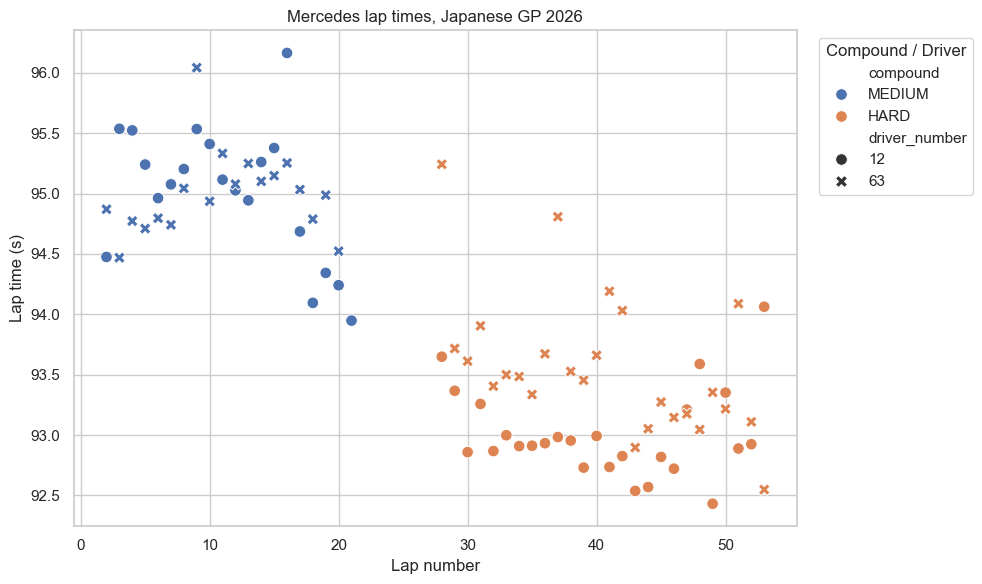

In [12]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=clean, x="lap_number", y="lap_duration",
    hue="compound", style="driver_number", s=70
)
plt.xlabel("Lap number")
plt.ylabel("Lap time (s)")
plt.title("Mercedes lap times, Japanese GP 2026")
plt.legend(title="Compound / Driver", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Interpretation:** lap times fall across the race. Medium laps (first stint) sit around 94 to 96 s and Hard laps (second stint) around 92.5 to 93.5 s. The two drivers follow the same pattern, so the difference between them is small. A few slow laps stand out (about 95 to 96 s). 

**Plot 2:** lap time against tyre age with a fitted line per compound. 

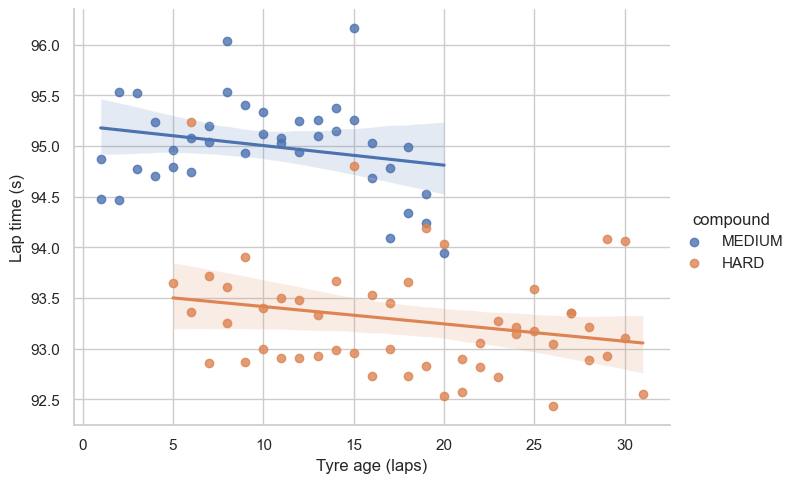

In [13]:
sns.lmplot(
    data=clean, x="tyre_age", y="lap_duration",
    hue="compound", height=5, aspect=1.4
)
plt.xlabel("Tyre age (laps)")
plt.ylabel("Lap time (s)")
plt.show()

**Interpretation:** both lines slope slightly **down**, not up. Degradation exists, but fuel burn improves pace by more, so the net effect is that cars get faster. This is why a simple "lap time vs tyre age" regression cannot measure degradation here, and it motivates controlling for lap number and compound.

In [14]:
removed = df[~df.index.isin(clean.index)]
removed[["driver_number", "lap_number", "lap_duration", "is_pit_out_lap"]].sort_values("lap_number")

,driver_number,lap_number,lap_duration,is_pit_out_lap
0,12,1,99.215,False
53,63,1,98.270,False
73,63,21,96.505,False
21,12,22,113.376,False
74,63,22,139.263,True
75,63,23,138.104,False
22,12,23,159.827,True
23,12,24,150.266,False
76,63,24,149.072,False
77,63,25,150.565,False


**Result:** lap 1 for both drivers (2), the two in-laps (RUS lap 21, ANT lap 22), the two out-laps (RUS lap 22, ANT lap 23) and nine slow laps between laps 23 and 27 (lap times of 138 to 151 s, against about 95 s normally).

In [15]:
rc = get("race_control", session_key=sk)
rc[rc["message"].str.contains("SAFETY CAR|VIRTUAL", case=False, na=False)][["lap_number", "message"]]

,lap_number,message
17,22,SAFETY CAR DEPLOYED
22,26,LAPPED CARS MAY NOW OVERTAKE THE SAFETY CAR: 77
25,27,SAFETY CAR IN THIS LAP


**Result:** the safety car was deployed on lap 22 and came in at the end of lap 27. Both Mercedes cars pitted under it, so the pit stops were cheap, and laps 22 to 27 are not normal racing laps. Removing them is justified.

In [16]:
clean.groupby("compound")["lap_duration"].agg(["count", "mean", "std", "min", "max"]).round(3)

,count,mean,std,min,max
compound,,,,,
HARD,52,93.280,0.553,92.432,95.242
MEDIUM,39,95.001,0.464,93.948,96.164


**Result:** Hard laps average 93.28 s (SD 0.55, n = 52) and Medium laps 95.00 s (SD 0.46, n = 39), a gap of about 1.7 s. Most of this gap comes from the Hard stint being later in the race (lighter car, more rubber on the track), not from the tyre alone.

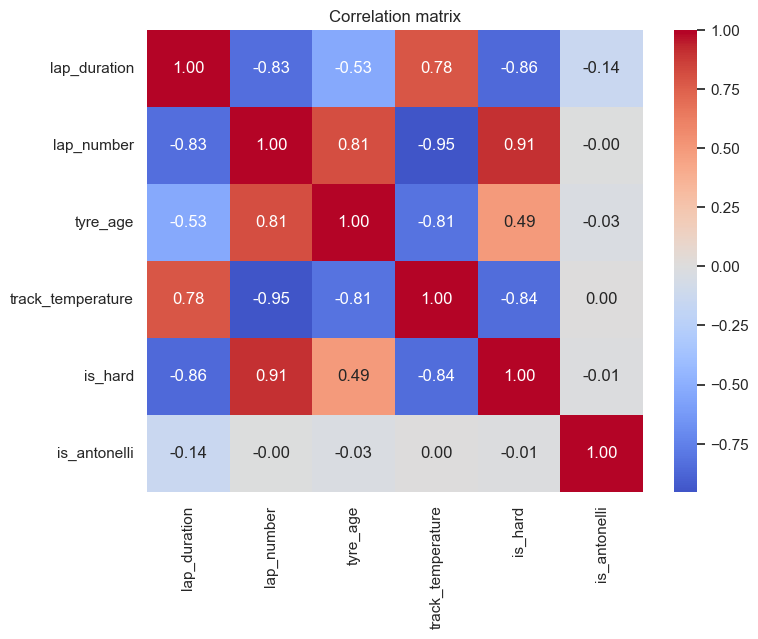

In [17]:
cols = ["lap_duration", "lap_number", "tyre_age", "track_temperature", "is_hard", "is_antonelli"]
plt.figure(figsize=(8, 6))
sns.heatmap(clean[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

**Interpretation:** lap time is strongly correlated with `is_hard` (-0.86), `lap_number` (-0.83) and `track_temperature` (+0.78). But the predictors are also strongly correlated with each other: `lap_number` with `track_temperature` (-0.95) and with `is_hard` (0.91). That signals **multicollinearity**. In a one-stop race, the track cools, the car gets lighter and the compound changes, all in step with lap number.

## 5. Multicollinearity (VIF)
**Concept.** The Variance Inflation Factor (VIF) shows how much a coefficient's variance is inflated because its predictor can be predicted from the other predictors. VIF = 1 means no overlap, and values above about 10 are usually treated as serious multicollinearity.

First VIF with the full set of candidate predictors.

In [18]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(clean[["lap_number", "tyre_age", "track_temperature", "is_hard"]])
vif = pd.DataFrame({
    "variable": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
vif

,variable,VIF
0,const,3618.248820
1,lap_number,1803.109963
2,tyre_age,424.003907
3,track_temperature,11.589293
4,is_hard,798.075546


**Result:** VIFs of 1803 (`lap_number`), 798 (`is_hard`) and 424 (`tyre_age`), and 11.6 for `track_temperature`. These predictors cannot be separated in this dataset. Within a stint, `tyre_age` is just `lap_number` minus a constant, and track temperature acts as a second clock. Keeping them all would make the coefficients unreliable.

**Decision:** drop `tyre_age` and `track_temperature`.

VIF for the **reduced model**: `lap_number`, `is_hard`, `is_antonelli`.

In [19]:
X = sm.add_constant(clean[["lap_number", "is_hard", "is_antonelli"]])
vif2 = pd.DataFrame({
    "variable": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
vif2

,variable,VIF
0,const,6.102538
1,lap_number,5.580080
2,is_hard,5.580850
3,is_antonelli,1.000412


**Result:** VIF is about 5.6 for `lap_number` and `is_hard`, and 1.0 for `is_antonelli`. All are below 10, so the reduced model is acceptable. The moderate overlap between `lap_number` and `is_hard` remains (the Hard stint is always the later one) and is stated as a limitation.

## 6. Regression models and inference
**Model 1 (simple):** lap_duration = b0 + b1 * lap_number
**Model 2 (multiple):** lap_duration = b0 + b1 * lap_number + b2 * is_hard + b3 * is_antonelli

Each coefficient is tested with a t-test (H0: beta = 0) and given a 95% confidence interval. The F-test checks whether the model as a whole is useful.

In [20]:
import statsmodels.formula.api as smf

m1 = smf.ols("lap_duration ~ lap_number", data=clean).fit()
m2 = smf.ols("lap_duration ~ lap_number + is_hard + is_antonelli", data=clean).fit()

print(m1.summary())
print(m2.summary())
print(m2.conf_int(alpha=0.05))

                            OLS Regression Results                            
Dep. Variable:           lap_duration   R-squared:                       0.694
Model:                            OLS   Adj. R-squared:                  0.691
Method:                 Least Squares   F-statistic:                     201.8
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           1.31e-24
Time:                        20:07:07   Log-Likelihood:                -74.651
No. Observations:                  91   AIC:                             153.3
Df Residuals:                      89   BIC:                             158.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     95.4663      0.117    812.785      0.0

**Model 1:** R2 = 0.694, adjusted R2 = 0.691, slope on `lap_number` = -0.052 s per lap (p < 0.001, 95% CI -0.059 to -0.045). Durbin-Watson = 1.00, so strong positive autocorrelation.

**Model 2:** R2 = 0.776, adjusted R2 = 0.769, F(3, 87) = 100.6, p < 0.001. Intercept 95.374 s.

| Coefficient | Estimate (s) | p-value | 95% CI |
|---|---|---|---|
| lap_number | -0.019 | 0.012 | -0.034 to -0.004 |
| is_hard | -1.163 | < 0.001 | -1.641 to -0.685 |
| is_antonelli | -0.305 | 0.003 | -0.506 to -0.105 |

**Interpretation:**
- Holding compound and driver fixed, each extra lap makes the car about 0.019 s faster. The slope is much smaller than in Model 1 (-0.052) because Model 1 left out the compound, so `lap_number` was absorbing the Medium-to-Hard gap (omitted variable bias).
- Laps in the Hard stint were about 1.16 s faster than in the Medium stint at the same lap number. This is the stint effect, and it is not the pure effect of the tyre, since the Hard stint is later, on a lighter car and a more rubbered-in track.
- Antonelli was about 0.31 s per lap faster than Russell after controlling for the other variables. 

**Does adding `is_hard` and `is_antonelli` help?** A nested-model F-test compares Model 1 with Model 2 (H0: the two extra coefficients are both zero).

In [21]:
from statsmodels.stats.anova import anova_lm
anova_lm(m1, m2)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,89.0,27.485385,0.0,NaN,NaN,NaN
1,87.0,20.093184,2.0,7.3922,16.003472,0.000001


**Result:** F = 16.00 on 2 and 87 degrees of freedom, p < 0.001. The sum of squared residuals falls from 27.49 to 20.09. We reject H0, so Model 2 is a significantly better fit than Model 1. It also has the lower AIC (128.8 vs 153.3) and BIC (138.8 vs 158.3).

## 7. Model diagnostics (Model 2)
OLS assumes the residuals are (1) centred on zero with constant variance, (2) approximately normal and (3) independent. Left: residuals against fitted values. Middle: Q-Q plot (points on the line mean normal). Right: histogram of residuals.

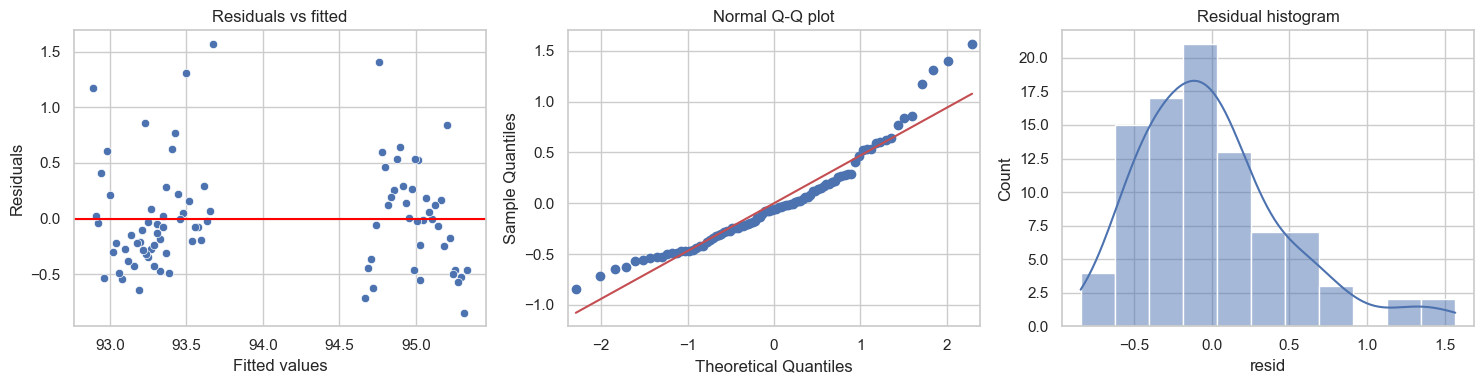

In [22]:
clean["fitted"] = m2.fittedvalues
clean["resid"] = m2.resid

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

sns.scatterplot(x=clean["fitted"], y=clean["resid"], ax=ax[0])
ax[0].axhline(0, color="red")
ax[0].set(title="Residuals vs fitted", xlabel="Fitted values", ylabel="Residuals")

sm.qqplot(clean["resid"], line="s", ax=ax[1])
ax[1].set_title("Normal Q-Q plot")

sns.histplot(clean["resid"], kde=True, ax=ax[2])
ax[2].set_title("Residual histogram")

plt.tight_layout()
plt.show()

**Interpretation:** the residuals-versus-fitted plot splits into two clusters (Medium fits near 95, Hard fits near 93), which is expected with a dummy variable, and there is no funnel shape. The Q-Q plot bends away from the line in the upper tail and the histogram is right-skewed, caused by a handful of unusually slow laps.

**Formal tests.**
- Breusch-Pagan: H0 = constant variance (homoscedasticity).
- Shapiro-Wilk: H0 = residuals are normal.
- Durbin-Watson: values near 2 mean no first-order autocorrelation, values well below 2 mean positive autocorrelation.

In [23]:
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats

bp = het_breuschpagan(m2.resid, m2.model.exog)
print("Breusch-Pagan p-value:", round(bp[1], 4))
print("Shapiro-Wilk p-value:", round(stats.shapiro(m2.resid)[1], 4))
print("Durbin-Watson:", round(sm.stats.durbin_watson(m2.resid), 3))

Breusch-Pagan p-value: 0.9967
Shapiro-Wilk p-value: 0.0001
Durbin-Watson: 1.527


**Results:**

| Assumption | Test | Result | Verdict |
|---|---|---|---|
| Constant variance | Breusch-Pagan | p = 0.997 | Not rejected, holds |
| Normality | Shapiro-Wilk | p = 0.0001 | Rejected, residuals right-skewed |
| Independence | Durbin-Watson | 1.53 (Model 1: 1.00) | Below 2, suggests positive autocorrelation |

Normality fails because of the skew, so t-tests and confidence intervals are only approximate, although with n = 91 the central limit theorem helps. Consecutive laps share conditions (traffic, track state), so autocorrelation is plausible, and this is what motivates the time series section. Compare 1.53 with the Durbin-Watson critical bounds in your course table (n about 90, 3 predictors) before quoting a verdict.

In [24]:
big = clean["resid"].abs().sort_values(ascending=False).index[:5]
clean.loc[big, ["driver_number", "lap_number", "compound", "lap_duration", "resid"]]

,driver_number,lap_number,compound,lap_duration,resid
80,63,28,HARD,95.242,1.569377
15,12,16,MEDIUM,96.164,1.403145
89,63,37,HARD,94.808,1.308309
52,12,53,HARD,94.063,1.176162
103,63,51,HARD,94.088,0.857315


**Result:** the five largest residuals are Russell lap 28 (+1.57 s), Antonelli lap 16 (+1.40), Russell lap 37 (+1.31), Antonelli lap 53 (+1.18) and Russell lap 51 (+0.86). Lap 28 is the first racing lap after the safety car came in (restart), and the others are probably traffic or a driver lifting, but the data does not say which. All are kept because they are real laps.

## 8. Time series analysis (AR, MA, ARMA)
A time series needs consecutive observations. Because of the safety car, the only long unbroken run is **Antonelli's Hard stint (laps 28 to 53)**, so that is the series. Inside one stint the compound and driver are fixed, which removes most of the structure the regression had to handle.

The cell below picks the stint, checks the laps are consecutive and plots the series. Change `DRIVER` and `STINT` to analyse another stint.

Driver 12, stint 2 (HARD): laps 28-53, n = 26


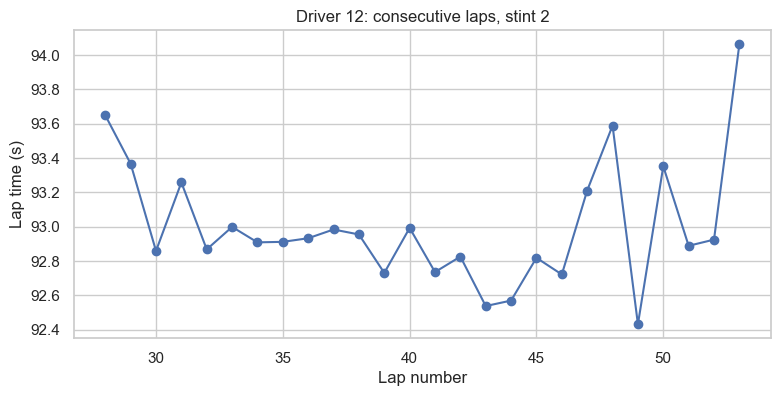

In [25]:
DRIVER = 12      # 12 = ANT, 63 = RUS
STINT  = 2       # 2 = HARD stint (post safety car); 1 = MEDIUM stint

sub = (clean[(clean["driver_number"] == DRIVER) & (clean["stint_number"] == STINT)]
       .sort_values("lap_number"))

run_id = (sub["lap_number"].diff() != 1).cumsum()
ts = sub[run_id == run_id.value_counts().idxmax()]

lap0 = int(ts["lap_number"].iloc[0])
y = pd.Series(ts["lap_duration"].to_numpy(),
              index=pd.RangeIndex(lap0, lap0 + len(ts), name="lap"), name="lap_duration")
X = pd.DataFrame({"lap": np.arange(len(y), dtype=float)}, index=y.index)

assert (np.diff(ts["lap_number"].to_numpy()) == 1).all(), "gap in the series"
print(f"Driver {DRIVER}, stint {STINT} ({ts['compound'].iloc[0]}): "
      f"laps {y.index[0]}-{y.index[-1]}, n = {len(y)}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(y.index, y.values, marker="o")
ax.set(xlabel="Lap number", ylabel="Lap time (s)",
       title=f"Driver {DRIVER}: consecutive laps, stint {STINT}")
plt.show()

**Result:** 26 consecutive laps (28 to 53) on the Hard tyre. The series is fairly flat, with a few spikes near laps 28 and 53.

**Stationarity.** ARMA models need a stationary series (stable mean and variance over time).
- **ADF test:** H0 = unit root (non-stationary). A small p-value means stationary.
- **KPSS test:** H0 = stationary. A small p-value means non-stationary.

Each is run around a constant and around a constant plus trend.

In [26]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss

rows = []
for reg, label in [("c", "constant"), ("ct", "constant + trend")]:
    adf_p = adfuller(y, maxlag=2, autolag="AIC", regression=reg)[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_p = kpss(y, regression=reg, nlags="auto")[1]
    rows.append({"around": label, "ADF p (H0: unit root)": round(adf_p, 3),
                 "KPSS p (H0: stationary)": round(kpss_p, 3)})
pd.DataFrame(rows)

,around,ADF p (H0: unit root),KPSS p (H0: stationary)
0,constant,0.001,0.10
1,constant + trend,0.925,0.01


**Result:**

| Around | ADF p (H0: unit root) | KPSS p (H0: stationary) |
|---|---|---|
| Constant | 0.001 | >= 0.10 |
| Constant + trend | 0.925 | 0.01 |

Around a constant, ADF rejects a unit root and KPSS does not reject stationarity, so the two tests agree: the series is stationary around a constant mean. The "constant + trend" row disagrees, but the next cell shows the fitted trend is essentially zero, so a constant is the right specification. No differencing is needed (d = 0).

**Detrending and the ACF/PACF.** We regress lap time on lap index and study the residuals.
- **ACF** (autocorrelation function): correlation of the series with itself at lag k. A cut-off after lag q suggests an MA(q).
- **PACF** (partial ACF): correlation at lag k after removing shorter lags. A cut-off after lag p suggests an AR(p).
- **Ljung-Box:** H0 = no autocorrelation up to the chosen lag.

Trend: -0.0000 s per lap  (p = 0.9970),  R2 = 0.000
Durbin-Watson: 1.524
Ljung-Box (lag 5) p-value: 0.2958


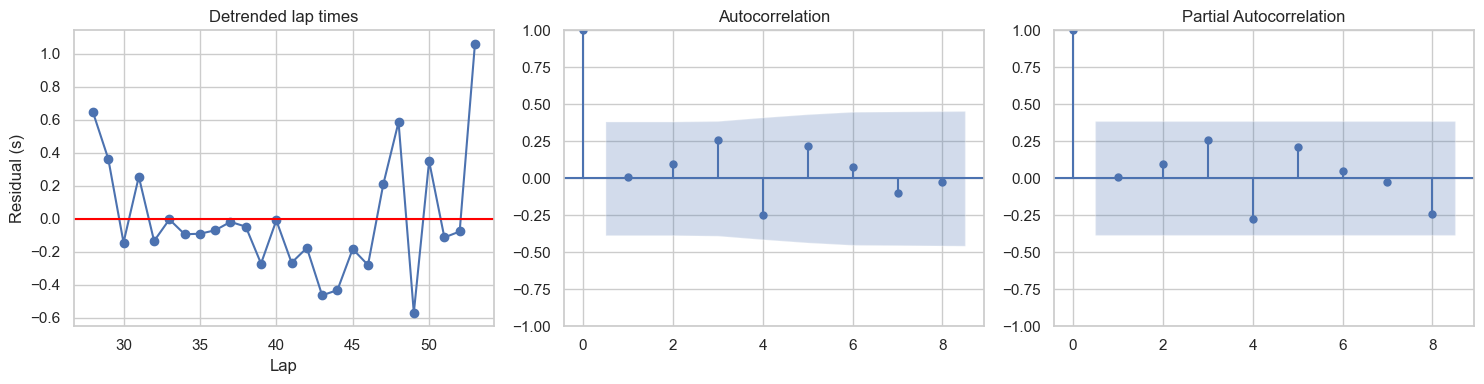

In [27]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

trend = sm.OLS(y, sm.add_constant(X)).fit()
r = trend.resid

print(f"Trend: {trend.params['lap']:+.4f} s per lap  (p = {trend.pvalues['lap']:.4f}),  R2 = {trend.rsquared:.3f}")
print("Durbin-Watson:", round(sm.stats.durbin_watson(r), 3))
print("Ljung-Box (lag 5) p-value:", round(acorr_ljungbox(r, lags=[5])["lb_pvalue"].iloc[0], 4))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(r.index, r.values, marker="o"); ax[0].axhline(0, color="red")
ax[0].set(title="Detrended lap times", xlabel="Lap", ylabel="Residual (s)")
plot_acf(r, lags=8, ax=ax[1])
plot_pacf(r, lags=8, method="ywm", ax=ax[2])
plt.tight_layout(); plt.show()

**Result:** the trend within the stint is -0.0000 s per lap (p = 0.997, R2 = 0), so lap time does not drift inside this stint. Fuel burn and tyre wear roughly cancel. Durbin-Watson = 1.52 and Ljung-Box (lag 5) p = 0.296, so no significant autocorrelation. All ACF and PACF bars lie inside the confidence band, so there is no clear AR or MA signature. The two largest residuals are at laps 28 (restart) and 53 (final lap).

**Fitting candidate models.** We fit every combination of AR order p = 0, 1, 2 and MA order q = 0, 1, 2 (including the lap index as a regressor) and compare them:
- **AR(p):** today's lap depends on the previous p laps.
- **MA(q):** today's lap depends on the previous q random shocks.
- **ARMA(p, q):** both.
- **AIC / AICc / BIC:** fit penalised for complexity, lower is better. AICc is the small-sample version and suits n = 26.
- **Ljung-Box p > 0.05:** residuals look like white noise, which is what we want.

In [28]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tools.sm_exceptions import ConvergenceWarning

def fit(order, endog=y, exog=X):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        return ARIMA(endog, exog=exog, order=(order[0], 0, order[1]), trend="c").fit()

fits, rows = {}, []
for p in range(3):
    for q in range(3):
        res = fit((p, q))
        fits[(p, q)] = res
        family = ("Trend only" if (p, q) == (0, 0) else
                  "AR" if q == 0 else "MA" if p == 0 else "ARMA")
        lb_p = acorr_ljungbox(res.resid, lags=[5], model_df=p + q)["lb_pvalue"].iloc[0]
        name = ("Trend only" if family == "Trend only" else
                f"AR({p})" if family == "AR" else
                f"MA({q})" if family == "MA" else f"ARMA({p},{q})")
        rows.append({"model": name, "family": family, "order": (p, q),
                     "AIC": res.aic, "AICc": res.aicc, "BIC": res.bic,
                     "LjungBox p (lag 5)": lb_p})

table = pd.DataFrame(rows).sort_values("AICc").reset_index(drop=True)
table[["model", "AIC", "AICc", "BIC", "LjungBox p (lag 5)"]].round(3)

c:\Users\nikit.LAPTOP-099SQUHM\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\nikit.LAPTOP-099SQUHM\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\nikit.LAPTOP-099SQUHM\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\nikit.LAPTOP-099SQUHM\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertib

,model,AIC,AICc,BIC,LjungBox p (lag 5)
0,Trend only,26.499,27.590,30.273,0.296
1,MA(2),25.696,28.696,31.987,0.448
2,AR(1),28.496,30.400,33.528,0.184
3,MA(1),28.496,30.401,33.529,0.186
4,AR(2),29.992,32.992,36.282,0.087
5,"ARMA(1,1)",30.496,33.496,36.787,0.103
6,"ARMA(1,2)",30.463,34.884,38.011,0.118
7,"ARMA(2,1)",31.207,35.628,38.756,0.054
8,"ARMA(2,2)",30.019,36.241,38.826,0.065


**Result (sorted by AICc):** trend only 27.59, MA(2) 28.70, AR(1) 30.40, MA(1) 30.40, AR(2) 32.99, ARMA(1,1) 33.50. The trend-only model has the **lowest AICc and BIC**, so adding AR or MA terms does not improve the fit once the small sample is penalised. MA(2) has the lowest plain AIC (25.70), but not the lowest AICc. All Ljung-Box p-values are above 0.05.

**Best model in each family.** Coefficient tables for the best AR, MA and ARMA model.

In [29]:
winners = {fam: table[table["family"] == fam].iloc[0] for fam in ["AR", "MA", "ARMA"]}
for fam, row in winners.items():
    print(f"\n=== best {fam}: {row['model']}  (AICc = {row['AICc']:.2f}) ===")
    print(fits[row["order"]].summary().tables[1])


=== best AR: AR(1)  (AICc = 30.40) ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         93.0044      0.155    598.884      0.000      92.700      93.309
lap         3.358e-06      0.008      0.000      1.000      -0.016       0.016
ar.L1          0.0148      0.243      0.061      0.951      -0.461       0.490
sigma2         0.1288      0.038      3.346      0.001       0.053       0.204

=== best MA: MA(2)  (AICc = 28.70) ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         93.0649      0.210    442.422      0.000      92.653      93.477
lap           -0.0009      0.012     -0.076      0.940      -0.024       0.022
ma.L1         -0.0180      0.117     -0.153      0.878      -0.248       0.212
ma.L2          0.7894      0.254      3.111      0.

**Result:**
- **AR(1):** phi = 0.015, p = 0.951, not significant.
- **MA(2):** theta1 = -0.018 (p = 0.878), theta2 = 0.789 (p = 0.002). Only the lag-2 term is significant, probably driven by the spikes at laps 28 and 53 in a series of 26 points.
- **ARMA(1,1):** AR and MA coefficients are both about 0.006 with standard errors near 27, so they are not identifiable (the two terms cancel). This model is not meaningful.

In plain terms: there is **no reliable autocorrelation** inside this stint.

**Residual diagnostics of the best AIC/AICc model among AR, MA and ARMA** (standardised residuals, histogram, Q-Q plot and correlogram), plus Ljung-Box and Shapiro-Wilk tests on its residuals.

Best overall among AR / MA / ARMA: MA(2)


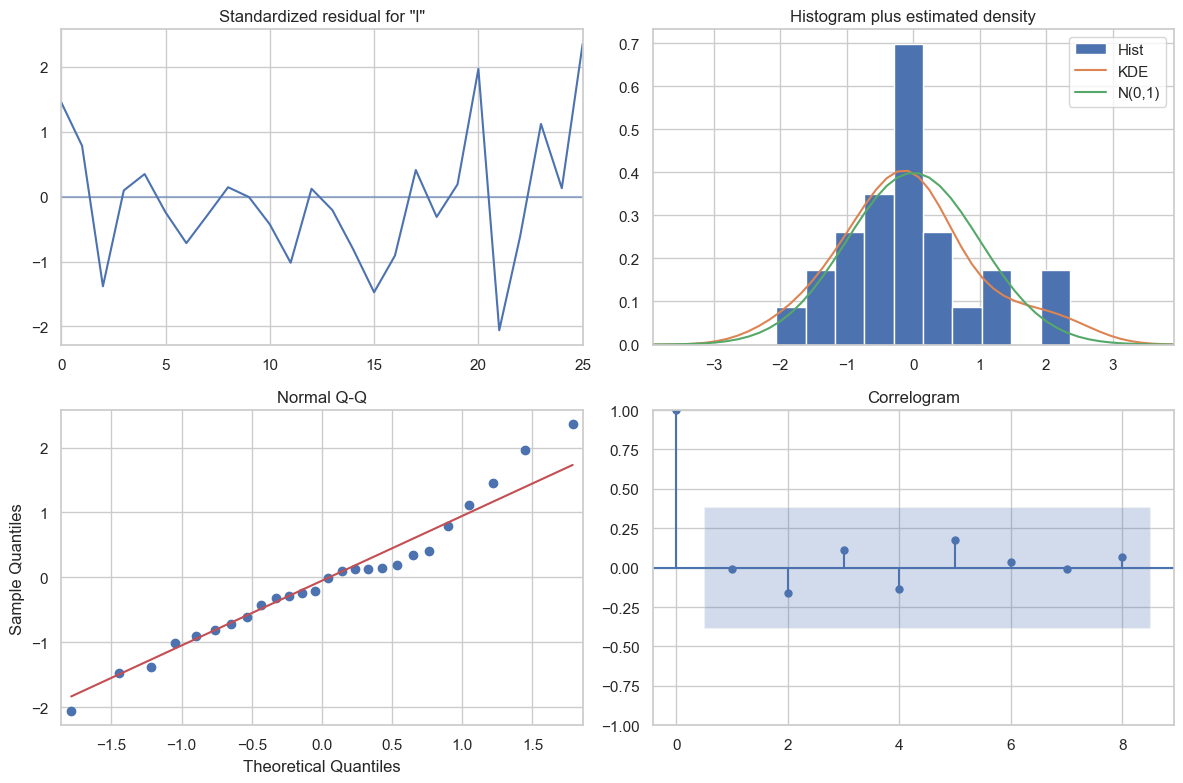

   lb_stat  lb_pvalue
3   1.3694     0.2419
5   2.6574     0.4475
8   2.8743     0.8244
Shapiro-Wilk p-value: 0.415


In [30]:
best_row = min(winners.values(), key=lambda r_: r_["AICc"])
best = fits[best_row["order"]]
print("Best overall among AR / MA / ARMA:", best_row["model"])

best.plot_diagnostics(figsize=(12, 8), lags=8)
plt.tight_layout(); plt.show()

print(acorr_ljungbox(best.resid, lags=[3, 5, 8], model_df=sum(best_row["order"])).round(4))
print("Shapiro-Wilk p-value:", round(stats.shapiro(best.resid)[1], 4))

**Result:** MA(2) is selected. Ljung-Box p-values are 0.24 (lag 3), 0.45 (lag 5) and 0.82 (lag 8), so the residuals are white noise. Shapiro-Wilk p = 0.415, so they are consistent with normality. The model is adequate, although it is not clearly better than the trend-only model.

## 9. Out-of-sample forecast check
**Concept.** A model that fits well in-sample can still forecast badly (overfitting). We hold out the **last 5 laps**, fit each model on the first 21 laps and compare forecast errors using RMSE (root mean squared error, in seconds, lower is better).

In [31]:
H = 5
y_tr, y_te = y.iloc[:-H], y.iloc[-H:]
X_tr, X_te = X.iloc[:-H], X.iloc[-H:]

candidates = {"Trend only": (0, 0)}
candidates.update({row["model"]: row["order"] for row in winners.values()})

out = []
for name, order in candidates.items():
    res = fit(order, endog=y_tr, exog=X_tr)
    fc = res.forecast(steps=H, exog=X_te)
    out.append({"model": name, "RMSE (s)": np.sqrt(np.mean((y_te.values - fc.values) ** 2))})
pd.DataFrame(out).round(3)

c:\Users\nikit.LAPTOP-099SQUHM\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'


,model,RMSE (s)
0,Trend only,0.664
1,AR(1),0.651
2,MA(2),0.682
3,"ARMA(1,1)",0.635


**Result:**

| Model | RMSE (s) |
|---|---|
| Trend only | 0.664 |
| AR(1) | 0.651 |
| MA(2) | 0.682 |
| ARMA(1,1) | 0.635 |

The differences are only about 0.05 s, and the test set has just 5 laps, so no model is clearly better. MA(2), the best in-sample AIC model, had the **worst** forecast RMSE, which hints at overfitting. The sensible conclusion is that a constant mean describes this stint about as well as any ARMA model.

## 10. Conclusions and limitations
**Findings**
1. Mercedes lap times fell through the race: fuel burn outweighs tyre wear at Suzuka, so the slope on lap number is negative (-0.019 s per lap in the multiple model).
2. Laps in the Hard stint were about 1.16 s faster and Antonelli about 0.31 s per lap faster than Russell. All three effects are significant at 5%, and the nested F-test (F = 16.0) confirms Model 2 beats Model 1.
3. Multicollinearity forced us to drop `tyre_age` and `track_temperature` (VIF fell from about 1800 to about 5.6).
4. Residuals have constant variance but are not normal (right-skewed) and show mild positive autocorrelation (DW 1.53).
5. Inside Antonelli's Hard stint, lap times are stationary around a constant with no trend and no reliable autocorrelation. AR, MA and ARMA models add little over a constant mean.

**Limitations**
- One race, two drivers and 91 laps, so results describe this race and cannot be generalised.
- The Hard stint is always the later one, so compound, fuel load, track evolution and the safety car are confounded.
- Pure tyre degradation could not be isolated because `tyre_age` and `lap_number` are nearly collinear.
- Traffic, fuel load and engine modes are not available in the data.
- The time series has only 26 points and a 5-lap hold-out.
- Normality of residuals fails, so p-values and intervals are approximate.